# SQL business analytics: the Chinook digital music store
Eight business questions answered in **SQL** (CTEs, joins, aggregations, window functions) against a SQLite database of customers, invoices, tracks, genres and employees, the same pattern used for analysing any ERP or sales database.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import sqlite3
con = sqlite3.connect("data/chinook.sqlite")
q = lambda sql: pd.read_sql_query(sql, con)
q("SELECT name AS table_name FROM sqlite_master WHERE type='table' ORDER BY 1").T

,0,1,2,3,4,5,6,7,8,9,10
table_name,Album,Artist,Customer,Employee,Genre,Invoice,InvoiceLine,MediaType,Playlist,PlaylistTrack,Track


### 1. Revenue by genre

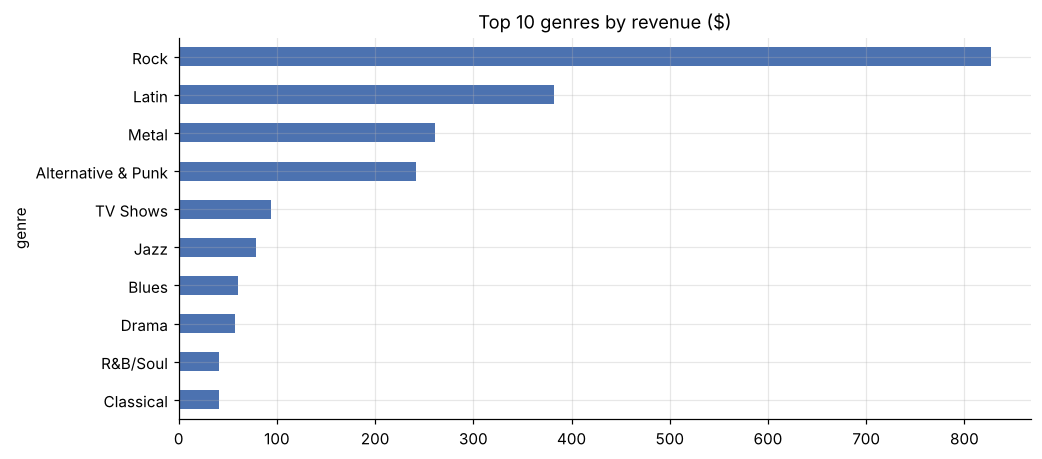

,genre,revenue,tracks_sold
0,Rock,826.65,835
1,Latin,382.14,386
2,Metal,261.36,264
3,Alternative & Punk,241.56,244
4,TV Shows,93.53,47
5,Jazz,79.20,80
6,Blues,60.39,61
7,Drama,57.71,29
8,R&B/Soul,40.59,41
9,Classical,40.59,41


In [2]:
genre = q("""
SELECT g.Name AS genre, ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue, SUM(il.Quantity) AS tracks_sold
FROM InvoiceLine il JOIN Track t ON t.TrackId = il.TrackId JOIN Genre g ON g.GenreId = t.GenreId
GROUP BY g.Name ORDER BY revenue DESC LIMIT 10""")
genre.set_index("genre").revenue.sort_values().plot.barh(color="#4C72B0"); plt.title("Top 10 genres by revenue ($)"); plt.show()
genre

### 2. Sales by country: customers, revenue, average order value

In [3]:
q("""
WITH c AS (SELECT Country, COUNT(*) AS customers FROM Customer GROUP BY Country)
SELECT i.BillingCountry AS country, c.customers, COUNT(*) AS orders, ROUND(SUM(i.Total), 2) AS revenue,
       ROUND(AVG(i.Total), 2) AS avg_order_value, ROUND(SUM(i.Total) / c.customers, 2) AS revenue_per_customer
FROM Invoice i JOIN c ON c.Country = i.BillingCountry
GROUP BY i.BillingCountry ORDER BY revenue DESC LIMIT 10""")

,country,customers,orders,revenue,avg_order_value,revenue_per_customer
0,USA,13,91,523.06,5.75,40.24
1,Canada,8,56,303.96,5.43,37.99
2,France,5,35,195.10,5.57,39.02
3,Brazil,5,35,190.10,5.43,38.02
4,Germany,4,28,156.48,5.59,39.12
5,United Kingdom,3,21,112.86,5.37,37.62
6,Czech Republic,2,14,90.24,6.45,45.12
7,Portugal,2,14,77.24,5.52,38.62
8,India,2,13,75.26,5.79,37.63
9,Chile,1,7,46.62,6.66,46.62


### 3. Monthly revenue with running total and month-over-month growth (window functions)

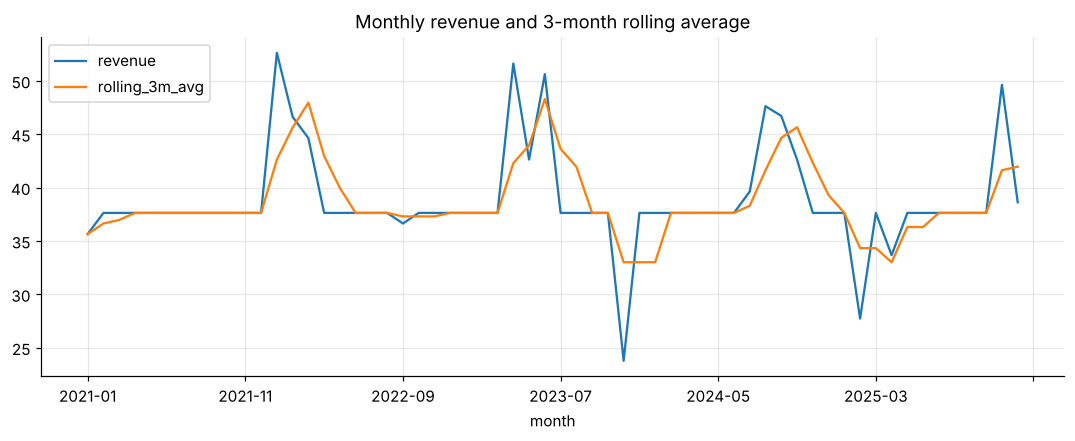

,month,revenue,running_total,mom_growth_pct,rolling_3m_avg
54,2025-07,37.62,2127.50,0.0,37.62
55,2025-08,37.62,2165.12,0.0,37.62
56,2025-09,37.62,2202.74,0.0,37.62
57,2025-10,37.62,2240.36,0.0,37.62
58,2025-11,49.62,2289.98,31.9,41.62
59,2025-12,38.62,2328.60,-22.2,41.95


In [4]:
monthly = q("""
WITH m AS (SELECT strftime('%Y-%m', InvoiceDate) AS month, SUM(Total) AS revenue FROM Invoice GROUP BY 1)
SELECT month, ROUND(revenue, 2) AS revenue,
       ROUND(SUM(revenue) OVER (ORDER BY month), 2) AS running_total,
       ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month)) / LAG(revenue) OVER (ORDER BY month), 1) AS mom_growth_pct,
       ROUND(AVG(revenue) OVER (ORDER BY month ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 2) AS rolling_3m_avg
FROM m ORDER BY month""")
ax = monthly.plot(x="month", y=["revenue", "rolling_3m_avg"], figsize=(12, 4)); ax.set_title("Monthly revenue and 3-month rolling average")
plt.savefig(IMG / "monthly_revenue.png", bbox_inches="tight"); plt.show(); monthly.tail(6)

### 4. Sales-rep performance and ranking

In [5]:
q("""
SELECT e.FirstName || ' ' || e.LastName AS sales_rep, e.Title, COUNT(DISTINCT c.CustomerId) AS customers,
       ROUND(SUM(i.Total), 2) AS revenue, RANK() OVER (ORDER BY SUM(i.Total) DESC) AS rank
FROM Employee e JOIN Customer c ON c.SupportRepId = e.EmployeeId JOIN Invoice i ON i.CustomerId = c.CustomerId
GROUP BY e.EmployeeId""")

,sales_rep,Title,customers,revenue,rank
0,Jane Peacock,Sales Support Agent,21,833.04,1
1,Margaret Park,Sales Support Agent,20,775.40,2
2,Steve Johnson,Sales Support Agent,18,720.16,3


### 5. Customer segmentation: RFM (recency, frequency, monetary) quintiles

In [6]:
rfm = q("""
WITH base AS (
  SELECT CustomerId, julianday((SELECT MAX(InvoiceDate) FROM Invoice)) - julianday(MAX(InvoiceDate)) AS recency_days,
         COUNT(*) AS frequency, SUM(Total) AS monetary
  FROM Invoice GROUP BY CustomerId)
SELECT b.*, c.FirstName || ' ' || c.LastName AS customer, c.Country,
       NTILE(5) OVER (ORDER BY recency_days DESC) AS R, NTILE(5) OVER (ORDER BY frequency) AS F, NTILE(5) OVER (ORDER BY monetary) AS M
FROM base b JOIN Customer c USING (CustomerId)""")
rfm["segment"] = np.select([(rfm.R >= 4) & (rfm.M >= 4), (rfm.R <= 2) & (rfm.M >= 4), rfm.R <= 2], ["Champions", "At risk (valuable)", "Lapsing"], "Regular")
rfm.groupby("segment").agg(customers=("CustomerId", "size"), avg_spend=("monetary", "mean"), avg_recency_days=("recency_days", "mean")).round(1)

,customers,avg_spend,avg_recency_days
segment,,,
At risk (valuable),6,43.0,349.7
Champions,10,41.7,46.6
Lapsing,18,37.8,390.3
Regular,25,38.9,108.2


### 6. Do customers buy whole albums or single tracks?

In [7]:
q("""
WITH inv_album AS (
  SELECT il.InvoiceId, t.AlbumId, COUNT(*) AS bought FROM InvoiceLine il JOIN Track t USING (TrackId) GROUP BY 1, 2),
album_size AS (SELECT AlbumId, COUNT(*) AS n FROM Track GROUP BY AlbumId),
flag AS (SELECT ia.InvoiceId, MAX(CASE WHEN ia.bought = a.n AND a.n > 2 THEN 1 ELSE 0 END) AS full_album
         FROM inv_album ia JOIN album_size a USING (AlbumId) GROUP BY ia.InvoiceId)
SELECT CASE full_album WHEN 1 THEN 'contains a full album' ELSE 'individual tracks only' END AS purchase_type,
       COUNT(*) AS invoices, ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM Invoice), 1) AS pct
FROM flag GROUP BY full_album""")

,purchase_type,invoices,pct
0,individual tracks only,412,100.0


### 7. Top artists and their best-selling track

In [8]:
q("""
WITH sales AS (
  SELECT ar.Name AS artist, t.Name AS track, SUM(il.Quantity) AS units
  FROM InvoiceLine il JOIN Track t USING (TrackId) JOIN Album al USING (AlbumId) JOIN Artist ar USING (ArtistId)
  GROUP BY ar.ArtistId, t.TrackId),
ranked AS (SELECT *, ROW_NUMBER() OVER (PARTITION BY artist ORDER BY units DESC, track) AS rn,
                  SUM(units) OVER (PARTITION BY artist) AS artist_units FROM sales)
SELECT artist, artist_units AS total_units, track AS best_track, units AS best_track_units
FROM ranked WHERE rn = 1 ORDER BY total_units DESC LIMIT 8""")

,artist,total_units,best_track,best_track_units
0,Iron Maiden,140,Aces High,2
1,U2,107,All Along The Watchtower,2
2,Metallica,91,Battery,2
3,Led Zeppelin,87,Bron-Y-Aur Stomp,2
4,Os Paralamas Do Sucesso,45,Mensagen De Amor (2000),2
5,Deep Purple,44,Maybe I'm A Leo,2
6,Faith No More,42,Caffeine,2
7,Lost,41,Walkabout,2


### 8. Media types and catalogue utilisation

In [9]:
q("""
SELECT mt.Name AS media_type, COUNT(DISTINCT t.TrackId) AS catalogue_tracks, COUNT(DISTINCT il.TrackId) AS tracks_ever_sold,
       ROUND(100.0 * COUNT(DISTINCT il.TrackId) / COUNT(DISTINCT t.TrackId), 1) AS pct_catalogue_sold,
       ROUND(SUM(il.UnitPrice * il.Quantity), 2) AS revenue
FROM Track t JOIN MediaType mt USING (MediaTypeId) LEFT JOIN InvoiceLine il ON il.TrackId = t.TrackId
GROUP BY mt.MediaTypeId ORDER BY revenue DESC""")

,media_type,catalogue_tracks,tracks_ever_sold,pct_catalogue_sold,revenue
0,MPEG audio file,3034,1745,57.5,1956.24
1,Protected MPEG-4 video file,214,103,48.1,220.89
2,Protected AAC audio file,237,129,54.4,144.54
3,Purchased AAC audio file,7,4,57.1,3.96
4,AAC audio file,11,3,27.3,2.97


**Takeaways for the business:** revenue is concentrated in a few genres and in the US, Canada and France; not a single invoice contains a complete album of three or more tracks (the only "complete" albums bought are 1-2 track singles), so per-track pricing and recommendations matter more than album bundles; and a large share of the catalogue never sells, which argues for curation or promotion of the long tail. RFM segments give marketing a ready target list (Champions to reward, valuable lapsing customers to win back).